# IND320 Assignment 3

## Links
- [GitHub repository](https://github.com/ptilrem/ptilrem-D2D-SLapp/tree/main)
- [Streamlit app](https://ptilrem-d2d-slapp.streamlit.app/)

# Tasks

## Imports

In [47]:
import geopandas as gpd
import pandas as pd
import requests
import matplotlib.pyplot as plt
import numpy as np
from scipy.fft import dct, idct
from sklearn.neighbors import LocalOutlierFactor
from statsmodels.tsa.seasonal import STL
from scipy.signal import spectrogram
from pathlib import Path

## Loading geographic regions and random sampling

In [48]:
# Read the regional boundaries from ZIP files
nve_regions = gpd.read_file("../data/NVE_Region.zip")
electricity_regions = gpd.read_file("../data/Budområder.zip")

# Inspect their columns and region identifiers
display(nve_regions.head())
display(electricity_regions.head())

,OBJECTID,REGION,REGIONNAVN,POSTNUMMER,POSTSTED,BESÃKSADR,ADRESSE,geometry
0,1.0,RV,Region Vest,6801,FÃ¸rde,Naustdalsveien 1B,Postboks 53,"POLYGON ((193105.76 6929797.839, 191705.75 692..."
1,2.0,RM,Region Midt-Norge,7030,Trondheim,"Abelsgate 9, Trondheim",Abelsgate 9,"POLYGON ((391250 7388620, 392270 7386790, 3937..."
2,3.0,RN,Region Nord,8514,Narvik,Kongensgate 52-54,Kongensgate 52-54,"POLYGON ((1109096.413 7844647.502, 1105115.343..."
3,4.0,RÃ,Region Ãst,2307,Hamar,Vangsvegen 73,Postboks 4223,"POLYGON ((253748.22 6678130.91, 253645.58 6678..."
4,5.0,RS,Region SÃ¸r,3103,TÃ¸nsberg,Anton Jenssens gate 7,Postboks 2124,"POLYGON ((253748.22 6678130.91, 253917.63 6677..."


,objectid,budomr,globalid,st_area(sh,st_perimet,geometry
0,1.0,NO 1,NaN,6.052902e+10,1.657761e+06,"POLYGON ((337473.63 6970542.97, 337711.9 69703..."
1,2.0,NO 2,NaN,6.875969e+10,1.256473e+06,"POLYGON ((-9833.91 6726499.86, -9836 6726404.0..."
2,3.0,NO 3,NaN,1.042199e+11,1.773323e+06,"POLYGON ((308588.7 7261519.43, 313576.63 72590..."
3,4.0,NO 4,NaN,2.032500e+11,3.385499e+06,"POLYGON ((973920.93 7962739.19, 974922.77 7962..."
4,5.0,NO 5,NaN,3.334870e+10,1.106762e+06,"POLYGON ((101466.43 6881318.54, 101525.43 6881..."


In [49]:
# Combine NVE regions
nve_regions["area"] = nve_regions["OBJECTID"].astype(int).map({
    1: "West",    # RV
    2: "North",   # RM
    3: "North",   # RN
    4: "East",    # RØ
    5: "East"     # RS
})

# Merge the polygons belonging to each area
nve_areas = nve_regions.dissolve(by="area", as_index=False)

display(nve_areas[["area", "geometry"]])

,area,geometry
0,East,"POLYGON ((244204.94 6521981.68, 231754.99 6523..."
1,North,"POLYGON ((522969.98 7381455.32, 520050.96 7378..."
2,West,"POLYGON ((193105.76 6929797.839, 191705.75 692..."


In [50]:
# Use an equal-area coordinate system for random sampling.
nve = nve_areas[["area", "geometry"]].to_crs("EPSG:3035")

el = electricity_regions[["budomr", "geometry"]].rename(
    columns={"budomr": "area"}
).to_crs("EPSG:3035")
el["area"] = el["area"].str.replace(" ", "", regex=False)

# Combine all eight regions into one GeoDataFrame.
regions = gpd.GeoDataFrame(
    pd.concat([nve, el], ignore_index=True),
    geometry="geometry",
    crs="EPSG:3035"
)

# Sample 1,000 points inside each region.
regions["geometry"] = regions.geometry.sample_points(1000, rng=42)

# Separate the points and convert to latitude/longitude.
locations = regions.explode(ignore_index=True).to_crs("EPSG:4326")
locations["latitude"] = locations.geometry.y
locations["longitude"] = locations.geometry.x

# Verify the result.
print("Total locations:", len(locations))
display(locations.groupby("area").size())
display(locations[["area", "latitude", "longitude"]].head())

Total locations: 8000


area
East     1000
NO1      1000
NO2      1000
NO3      1000
NO4      1000
NO5      1000
North    1000
West     1000
dtype: int64

,area,latitude,longitude
0,East,62.093330,8.284570
1,East,58.770033,5.676368
2,East,60.307476,11.145033
3,East,62.026214,7.679507
4,East,61.264602,8.563117


In [51]:
# Save the sampled region coordinates for use in Streamlit.
region_locations = locations[["area", "latitude", "longitude"]].copy()

region_locations.to_parquet(
    "../data/region_locations.parquet",
    index=False
)

print("Saved locations:", len(region_locations))
display(region_locations.groupby("area").size())

Saved locations: 8000


area
East     1000
NO1      1000
NO2      1000
NO3      1000
NO4      1000
NO5      1000
North    1000
West     1000
dtype: int64

## Historical weather data and Open-Mentro ERA5

I got 1000 random locations per region from the shapefiles (8000 total). For the 2024 weather analysis I downloaded 100 sampled locations in NO1-3, but I wasn't able to download more as I hit the API rate limits. More can be downloaded in the future.

In [63]:
# Download ERA5 weather and average the measurements across sampled locations.
def download_weather(region, start_date, end_date, n_locations=5, start_index=0):
    region_points = locations[locations["area"] == region]
    points = region_points.iloc[start_index:start_index + n_locations]

    if points.empty:
        raise ValueError(f"Unknown region: {region}")

    params = {
        "latitude": ",".join(points["latitude"].astype(str)),
        "longitude": ",".join(points["longitude"].astype(str)),
        "start_date": start_date,
        "end_date": end_date,
        "hourly": "temperature_2m,precipitation",
        "models": "era5",
        "timezone": "UTC"
    }

    response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params=params,
        timeout=120
    )
    response.raise_for_status()

    results = response.json()
    if isinstance(results, dict):
        results = [results]

    # Average hourly values across the requested locations.
    frames = [pd.DataFrame(result["hourly"]) for result in results]
    weather = (
        pd.concat(frames)
        .groupby("time", as_index=False)[["temperature_2m", "precipitation"]]
        .mean()
    )
    weather["time"] = pd.to_datetime(weather["time"], utc=True)

    return weather

In [ ]:
DATA_DIR = Path("../data")
BATCH_DIR = DATA_DIR / "weather_batches"
BATCH_DIR.mkdir(parents=True, exist_ok=True)


def download_region_weather(region, year=2024, n_locations=100, batch_size=10):
    """Return hourly ERA5 weather averaged over n_locations sampled points.

    Downloads in small batches to respect Open-Meteo's rate limits. Each batch
    is saved, so a run interrupted by a 429 error can resume where it stopped.
    """
    final_file = DATA_DIR / f"weather_{region}_{year}_{n_locations}locations.parquet"
    if final_file.exists():
        return pd.read_parquet(final_file)

    batches = []
    for start in range(0, n_locations, batch_size):
        end = start + batch_size
        batch_file = BATCH_DIR / f"{region}_{year}_{start:04d}_{end:04d}.parquet"

        if not batch_file.exists():
            batch = download_weather(
                region, f"{year}-01-01", f"{year}-12-31",
                n_locations=batch_size, start_index=start
            )
            batch.to_parquet(batch_file, index=False)
        batches.append(pd.read_parquet(batch_file))

    # Equal-sized batches, so averaging the batch means gives the overall mean.
    weather = (
        pd.concat(batches)
        .groupby("time", as_index=False)[["temperature_2m", "precipitation"]]
        .mean()
    )
    weather["time"] = pd.to_datetime(weather["time"], utc=True)
    weather.to_parquet(final_file, index=False)
    return weather


# Regions downloaded before the API started returning HTTP 429 errors.
for region in ["NO1", "NO2", "NO3"]:
    weather = download_region_weather(region)
    print(f"{region}: {len(weather)} hourly observations")

weather_no3 = download_region_weather("NO3")  # Used for the analyses below

Batches combined: 10
Locations represented: 100
Hourly observations: 8784


,time,temperature_2m,precipitation
0,2024-01-01 00:00:00+00:00,-4.003,0.003
1,2024-01-01 01:00:00+00:00,-4.130,0.001
2,2024-01-01 02:00:00+00:00,-4.083,0.001
3,2024-01-01 03:00:00+00:00,-4.094,0.001
4,2024-01-01 04:00:00+00:00,-4.045,0.001


In [57]:
# Calculate daily weather values from the hourly ERA5 data.
daily_weather = (
    weather_no3_100.set_index("time")
    .resample("D")
    .agg({
        "precipitation": "sum",
        "temperature_2m": "mean"
    })
    .reset_index()
)

daily_weather = daily_weather.rename(columns={
    "precipitation": "precipitation_mm",
    "temperature_2m": "temperature_c"
})

print("Daily observations:", len(daily_weather))
display(daily_weather.head())

Daily observations: 366


,time,precipitation_mm,temperature_c
0,2024-01-01 00:00:00+00:00,0.079,-4.644000
1,2024-01-02 00:00:00+00:00,0.097,-7.519833
2,2024-01-03 00:00:00+00:00,0.003,-9.897875
3,2024-01-04 00:00:00+00:00,0.307,-11.456333
4,2024-01-05 00:00:00+00:00,1.025,-10.246083


## Precipitation outliers (DCT and SPC)

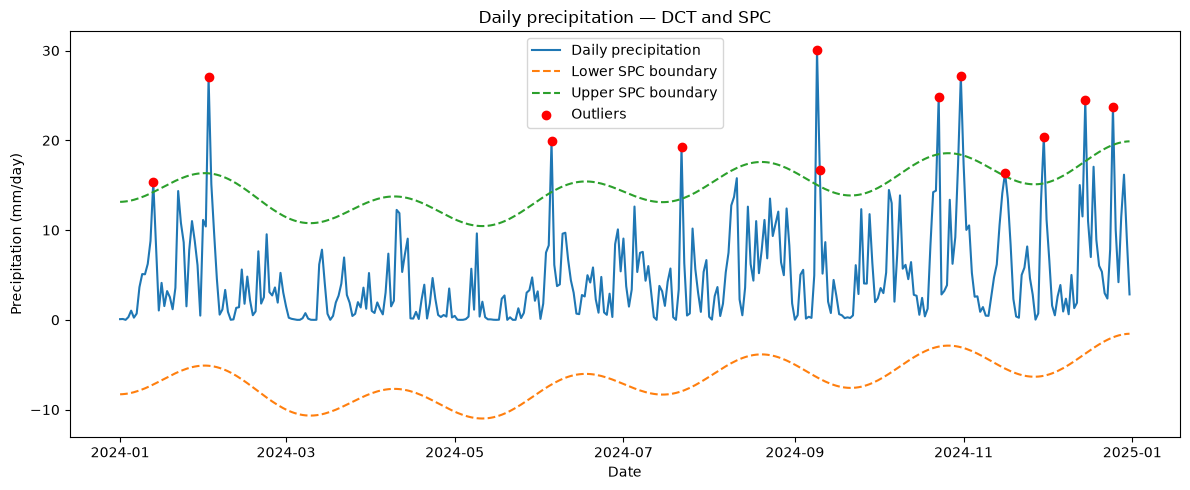

Outliers detected: 12 of 366 days


,time,precipitation_mm
12,2024-01-13 00:00:00+00:00,15.352
32,2024-02-02 00:00:00+00:00,26.998
156,2024-06-05 00:00:00+00:00,19.880
203,2024-07-22 00:00:00+00:00,19.205
252,2024-09-09 00:00:00+00:00,30.087


In [ ]:
# Detect precipitation outliers using DCT filtering and robust SPC boundaries.
def plot_precipitation_spc(data, cutoff=12, n_std=3):
    precipitation = data["precipitation_mm"].to_numpy()

    # Keep only the `cutoff` lowest DCT frequencies (the slow seasonal trend).
    # For one year of data, cutoff=12 keeps variations slower than about 2 months.
    coefficients = dct(precipitation, norm="ortho")
    coefficients[cutoff:] = 0
    trend = idct(coefficients, norm="ortho")

    # Subtracting the trend leaves the high-pass filtered values (SATV).
    satv = precipitation - trend

    # Estimate the centre and standard deviation using robust statistics.
    centre = np.median(satv)
    sigma = 1.4826 * np.median(np.abs(satv - centre))

    lower = trend + centre - n_std * sigma
    upper = trend + centre + n_std * sigma

    # Identify observations outside the SPC boundaries.
    mask = (precipitation < lower) | (precipitation > upper)
    outliers = data.loc[mask, ["time", "precipitation_mm"]].copy()

    # Plot precipitation and its boundaries, but not SATV itself.
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(data["time"], precipitation, label="Daily precipitation")
    ax.plot(data["time"], lower, "--", label="Lower SPC boundary")
    ax.plot(data["time"], upper, "--", label="Upper SPC boundary")
    ax.scatter(
        outliers["time"],
        outliers["precipitation_mm"],
        color="red",
        label="Outliers",
        zorder=3
    )

    ax.set_title("Daily precipitation — DCT and SPC")
    ax.set_xlabel("Date")
    ax.set_ylabel("Precipitation (mm/day)")
    ax.legend()
    fig.tight_layout()

    return fig, outliers


# Test the analysis using the NO3 weather data for 2024.
fig, outliers = plot_precipitation_spc(daily_weather)

plt.show()
print(f"Outliers detected: {len(outliers)} of {len(daily_weather)} days")
display(outliers.head())

## Temperature anomalies (LOF)

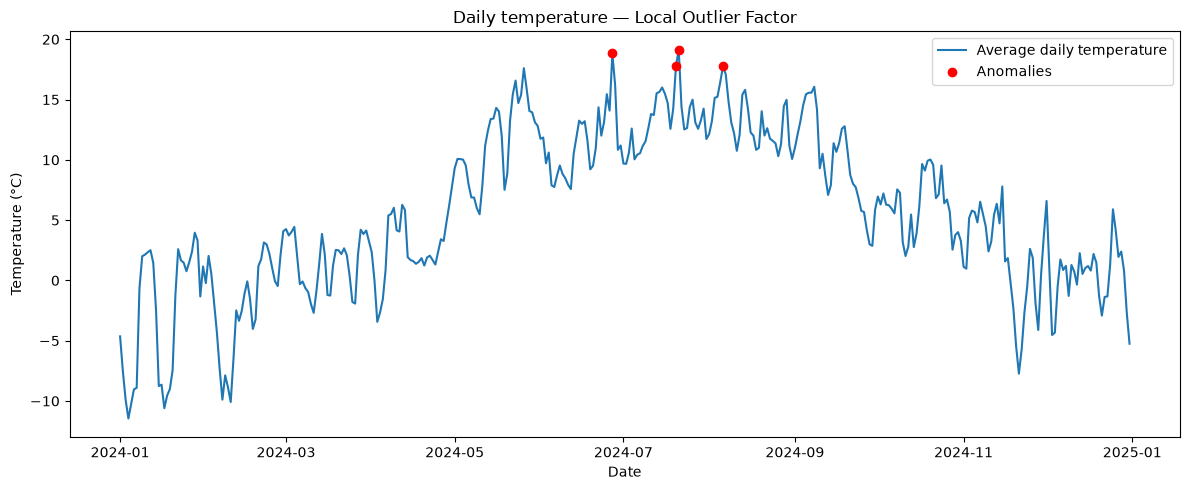

Anomalies detected: 4 of 366 days


,time,temperature_c
178,2024-06-27 00:00:00+00:00,18.821125
201,2024-07-20 00:00:00+00:00,17.800833
202,2024-07-21 00:00:00+00:00,19.130500
218,2024-08-06 00:00:00+00:00,17.749208


In [ ]:
# Detect unusual daily temperatures using Local Outlier Factor.
def plot_temperature_lof(data, outlier_fraction=0.01):
    temperatures = data[["temperature_c"]]

    # LOF returns -1 for anomalies and 1 for normal observations.
    lof = LocalOutlierFactor(
        n_neighbors=20,
        contamination=outlier_fraction
    )
    mask = lof.fit_predict(temperatures) == -1

    anomalies = data.loc[mask, ["time", "temperature_c"]].copy()

    # Plot the original temperatures and highlight anomalies.
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(
        data["time"],
        data["temperature_c"],
        label="Average daily temperature"
    )
    ax.scatter(
        anomalies["time"],
        anomalies["temperature_c"],
        color="red",
        label="Anomalies",
        zorder=3
    )

    ax.set_title("Daily temperature — Local Outlier Factor")
    ax.set_xlabel("Date")
    ax.set_ylabel("Temperature (°C)")
    ax.legend()
    fig.tight_layout()

    return fig, anomalies


# Test using NO3 weather data for 2024.
fig, anomalies = plot_temperature_lof(daily_weather)

plt.show()
print(f"Anomalies detected: {len(anomalies)} of {len(daily_weather)} days")
display(anomalies)

## Reservoir Filling Data from NVE

In [60]:
# Retrieve the weekly reservoir filling data from NVE.
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(url, timeout=90)
response.raise_for_status()

reservoir_df = pd.DataFrame(response.json())

# Select nationwide reservoir statistics.
reservoir_df = reservoir_df[
    (reservoir_df["omrType"] == "NO") &
    (reservoir_df["omrnr"] == 0)
].copy()

# Keep the date and degree of filling.
reservoir_df = reservoir_df.rename(columns={
    "dato_Id": "date_id",
    "fyllingsgrad": "fill_percentage"
})

reservoir_df["date_id"] = pd.to_datetime(reservoir_df["date_id"])
reservoir_df = reservoir_df.sort_values("date_id")

print("Weekly observations:", len(reservoir_df))
print("Date range:", reservoir_df["date_id"].min(), "to", reservoir_df["date_id"].max())

display(reservoir_df[["date_id", "fill_percentage"]].head())

Weekly observations: 1661
Date range: 1995-01-08 00:00:00 to 2026-11-01 00:00:00


,date_id,fill_percentage
9941,1995-01-08,0.603830
9885,1995-01-15,0.578233
9848,1995-01-22,0.558350
9822,1995-01-29,0.530596
9887,1995-02-05,0.502755


## Seasonal-Trend Decomposition

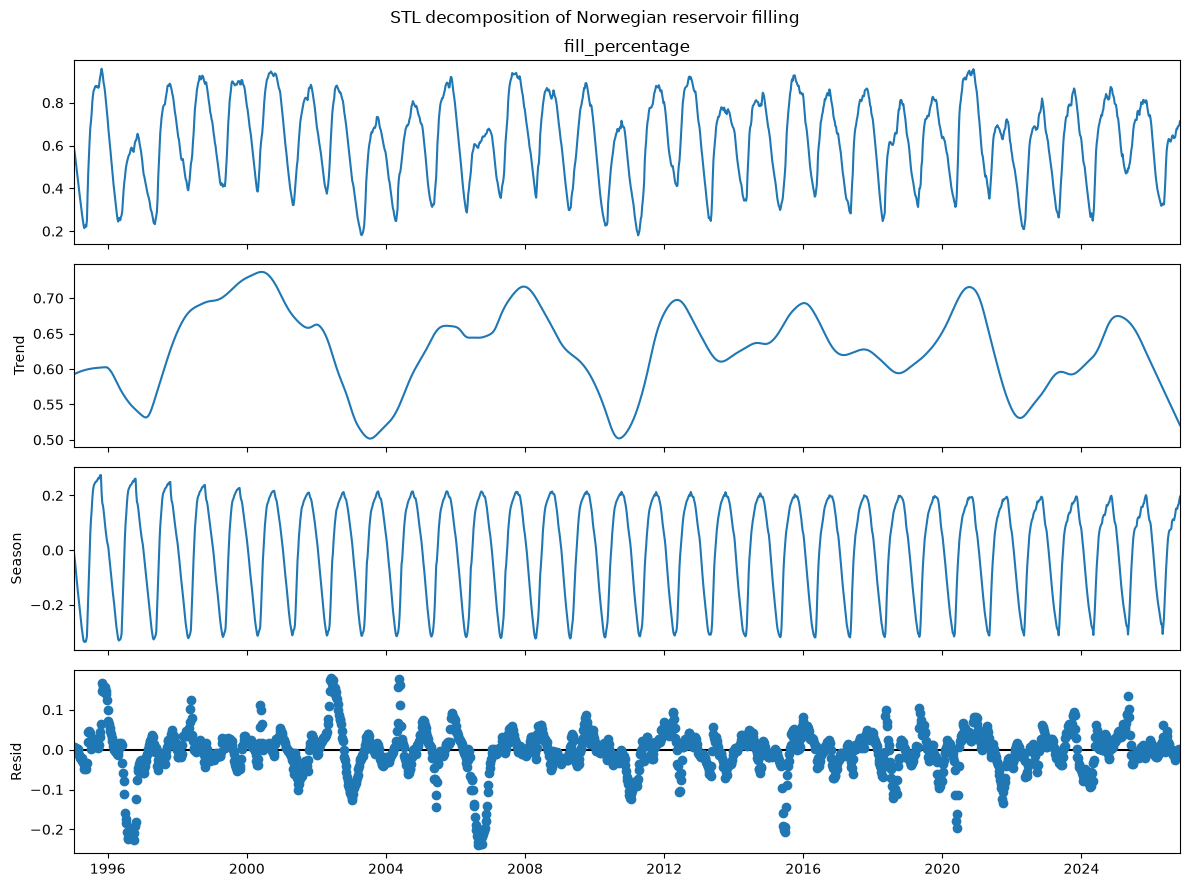

In [ ]:
def weekly_filling(data):
    """Return the reservoir filling as a regular, gap-free weekly series."""
    return (
        data.set_index("date_id")["fill_percentage"]
        .astype(float)
        .resample("W-SUN")
        .mean()
        .interpolate()
    )


# Decompose weekly reservoir filling into trend, seasonal and residual components.
def plot_stl(data, seasonal=13, trend=101, robust=True):
    filling = weekly_filling(data)

    # Perform STL decomposition with a yearly seasonal cycle.
    result = STL(
        filling,
        period=52,
        seasonal=seasonal,
        trend=trend,
        robust=robust
    ).fit()

    # Plot the original series and its three components.
    fig = result.plot()
    fig.set_size_inches(12, 9)
    fig.suptitle("STL decomposition of Norwegian reservoir filling")
    fig.tight_layout()

    return fig


# Test the STL function.
fig = plot_stl(reservoir_df)
plt.show()

## Spectrogram analysis

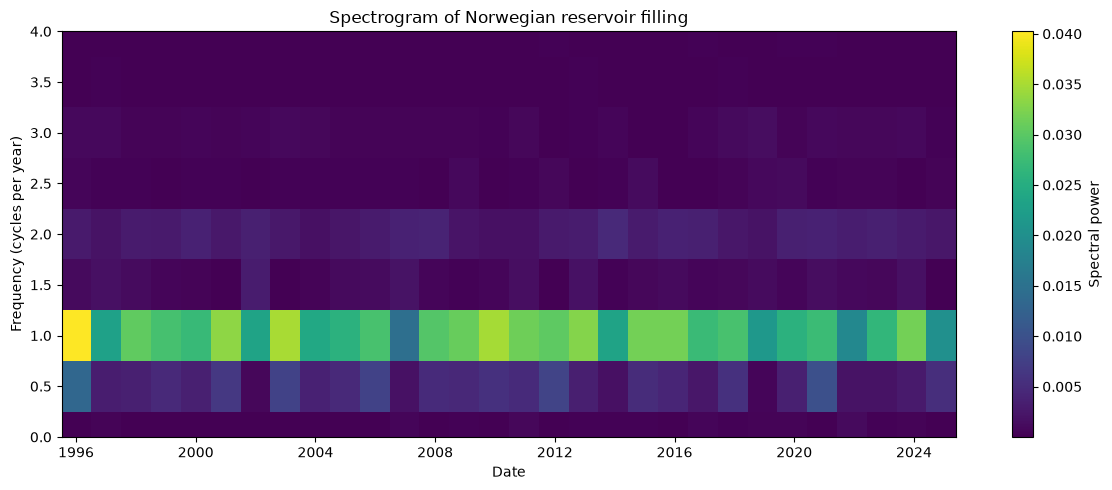

In [ ]:
# Plot how the frequencies in weekly reservoir filling change over time.
def plot_spectrogram(data, window_length=104, overlap=52):
    # Prepare the same weekly filling series used for STL.
    filling = weekly_filling(data)

    # Calculate the spectrogram using weekly observations.
    frequencies, times, power = spectrogram(
        filling.to_numpy(),
        fs=1,
        nperseg=window_length,
        noverlap=overlap,
        detrend="linear",
        scaling="spectrum"
    )

    # Convert the time and frequency axes to readable units.
    dates = filling.index[0] + pd.to_timedelta(times * 7, unit="D")
    cycles_per_year = frequencies * 52

    fig, ax = plt.subplots(figsize=(12, 5))
    image = ax.pcolormesh(
        dates, cycles_per_year, power, shading="auto"
    )

    ax.set_title("Spectrogram of Norwegian reservoir filling")
    ax.set_xlabel("Date")
    ax.set_ylabel("Frequency (cycles per year)")
    ax.set_ylim(0, 4)

    fig.colorbar(image, ax=ax, label="Spectral power")
    fig.tight_layout()

    return fig


# Test the spectrogram.
fig = plot_spectrogram(reservoir_df)
plt.show()

## Log

First I downloaded the NVE Atlas shapefiles for "Budområder" and "NVE_Region" from the NVE website and loaded them in using geopandas. I then merged RM and RN into "North" and RØ and RS into "East", to match the VASS regions we already had from previous exercises. I then sampled 1000 random locations inside each of the eight areas (the 3 new regions from NVE_Region, and 5 from Budområder) and saved their latitude/longitude pairs to a Parquet file so Streamlit could reuse them later and to avoid sending too many API requests.

To get the weather data I wrote a function that requests the hourly ERA5 temperature and precipitation from Open-Meteo for a region and date range and averages the values for some sampled locations. I tested it on NO3 for 2024, first only using 5 locations to make sure everything works before moving on to more locations. I then downloaded locations in batches of 10 and saved them in case I ran into an API limitation along the way, and then later combined 10 batches into 100 locations for NO1, NO2, and NO3 until I ran into the API limitations. The analysis in the notebook uses these 100 locations instead of 1000. For regions without saved data, the app uses live download of only 5 locations as I didn't want to run into more API limits on the regions that weren't covered. 

For the precipitation I summed the hourly values into daily totals and used DCT to estimate the slow seasonal component. I got SPC limits based on the mdeian and median absolute deviation of the remainder, and then marked the days that were outliers in red. For temperature I calculated the daily means and used LOF to mark unusual days. Both analyses are wrapped in a function and returns a plot and detected observations.

I also used the NVE API again to retrieve the weekly reservoir filling and used STL to split it into trend, seasonal and residual components, and then made a spectrogram to see how its frequency content changes. 

In Streamlit I added two more pages, one for the STL and spectrogram tabs, and one for the SPC and LOF tabs, each with sliders for the different method parameters. The area selection is shared across all the pages just like in assignment 2, using st.session_state. I also avoided reloading the weather data on every streamlit interaction by using st.cache_data like in the previous assignment. The main challenge I faced in this assignment was the API limits with being close to the deadline, so I couldn't fully download all the data for all the 8000 locations. 

## AI Usage

I used ChatGPT as an assistant throughout the assignment. It helped me understand the geographic sampling, Open-Meteo API responses and limits, DCT/SPC, and LOF methods. I also used it to draft and debug some of the code, helped implement caching and batch downloads, and adapt the analyses for Streamlit. I reported errors and results from my code, got feedback, and made decisions about which changes to keep.